# 1. Imports and global settings

In [1]:
import os

os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
os.environ["TF_ENABLE_ONEDNN_OPTS"] = "0"

In [2]:
import os
import random
import numpy as np
import torch
from torchvision import datasets, transforms
from tqdm import tqdm
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

tf.get_logger().setLevel("ERROR")

In [3]:
# Reproducibility seed
# Using a fixed seed helps make results more repeatable
SEED = 42

def fix_random_seed(seed=SEED):
    """Fix random seeds for reproducibility."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    tf.random.set_seed(seed)

fix_random_seed(SEED)

print("Setup complete")

Setup complete


# 2. Data loading

In [4]:
def load_data_pt(path):
    """
    Load one saved .pt split and convert it to Keras-friendly arrays.

    Returns
    -------
    images:
        NumPy array of shape [N, H, W, 3], values in [0, 1].

    labels:
        NumPy array of shape [N, 10].
        These are multi-hot labels used for training.
    """
    data = torch.load(path, map_location="cpu")

    # Convert [N, H, W] uint8 to [N, H, W, 1] float32.
    images = data["images"].numpy().astype("float32") / 255.0
    images = np.expand_dims(images, axis=-1)

    # ResNet expects 3-channel inputs, so replicate the grayscale channel.
    images = np.repeat(images, repeats=3, axis=-1)

    # Multi-label targets.
    labels = data["labels"].numpy().astype("float32")

    # Extra metadata, not required for model training.
    center_labels = data["center_labels"].numpy().astype("int64")
    count_labels = data["count_labels"].numpy().astype("int64")

    meta = {
        "center_labels": center_labels,
        "count_labels": count_labels,
        "num_digits": data["num_digits"].numpy().astype("int64"),
        "all_digit_labels": data["all_digit_labels"].numpy().astype("int64"),
        "all_positions": data["all_positions"].numpy().astype("int64"),
        "label_type": data.get("label_type", None),
    }

    return images, labels, meta

In [ ]:
def build_histograms(all_digit_labels):
    """Build per-image digit count histograms from padded digit labels."""
    histograms = []
    for sample_labels in all_digit_labels:
        hist = np.zeros(10, dtype=np.float32)
        for d in sample_labels:
            if d >= 0:
                hist[d] += 1
        histograms.append(hist)
    return np.stack(histograms, axis=0).astype(np.float32)

def build_position_targets(meta_positions, image_size=64):
    """Normalize digit top-left coordinates and preserve -1 padding."""
    positions = meta_positions.astype(np.float32)
    valid = np.all(positions >= 0, axis=-1, keepdims=True)
    normalized = np.where(valid, positions / image_size, -1.0)
    return normalized.astype(np.float32)

In [6]:
# File paths for train, validation, and test.
train_path = os.path.join("./data/train.pt")
val_path = os.path.join("./data/val.pt")
test_path = os.path.join("./data/test.pt")

# Load files if they exist.
if all(os.path.exists(p) for p in [train_path, val_path, test_path]):
    x_train, y_train, meta_train = load_data_pt(train_path)
    x_val, y_val, meta_val = load_data_pt(val_path)
    x_test, y_test, meta_test = load_data_pt(test_path)

    y_train_hist = build_histograms(meta_train["all_digit_labels"] )
    y_val_hist = build_histograms(meta_val["all_digit_labels"] )
    y_test_hist = build_histograms(meta_test["all_digit_labels"] )
    y_train_positions = build_position_targets(meta_train["all_positions"])
    y_val_positions = build_position_targets(meta_val["all_positions"])
    y_test_positions = build_position_targets(meta_test["all_positions"])

    print("Data loaded successfully.")
    print("Train:", x_train.shape, y_train.shape, y_train_hist.shape, y_train_positions.shape)
    print("Val:  ", x_val.shape, y_val.shape, y_val_hist.shape, y_val_positions.shape)
    print("Test: ", x_test.shape, y_test.shape, y_test_hist.shape, y_test_positions.shape)
    print("You can now proceed to model training and evaluation.")
else:
    print("Dataset files not found yet.")


Data loaded successfully.
Train: (50000, 64, 64, 3) (50000, 10) (50000, 10) (50000, 8, 2)
Val:   (10000, 64, 64, 3) (10000, 10) (10000, 10) (10000, 8, 2)
Test:  (10000, 64, 64, 3) (10000, 10) (10000, 10) (10000, 8, 2)
You can now proceed to model training and evaluation.


# 3. Visualization

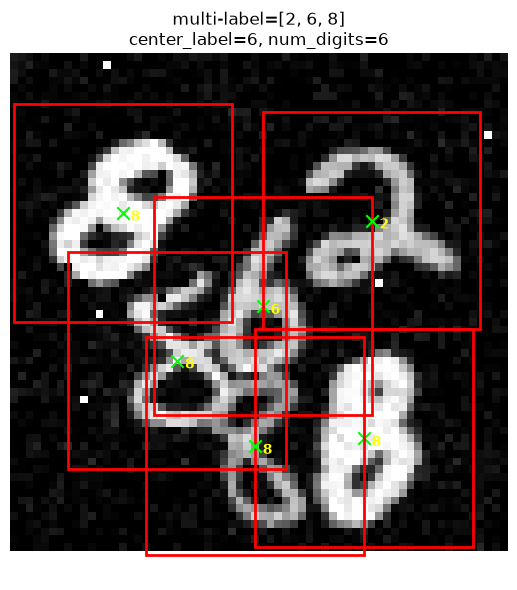

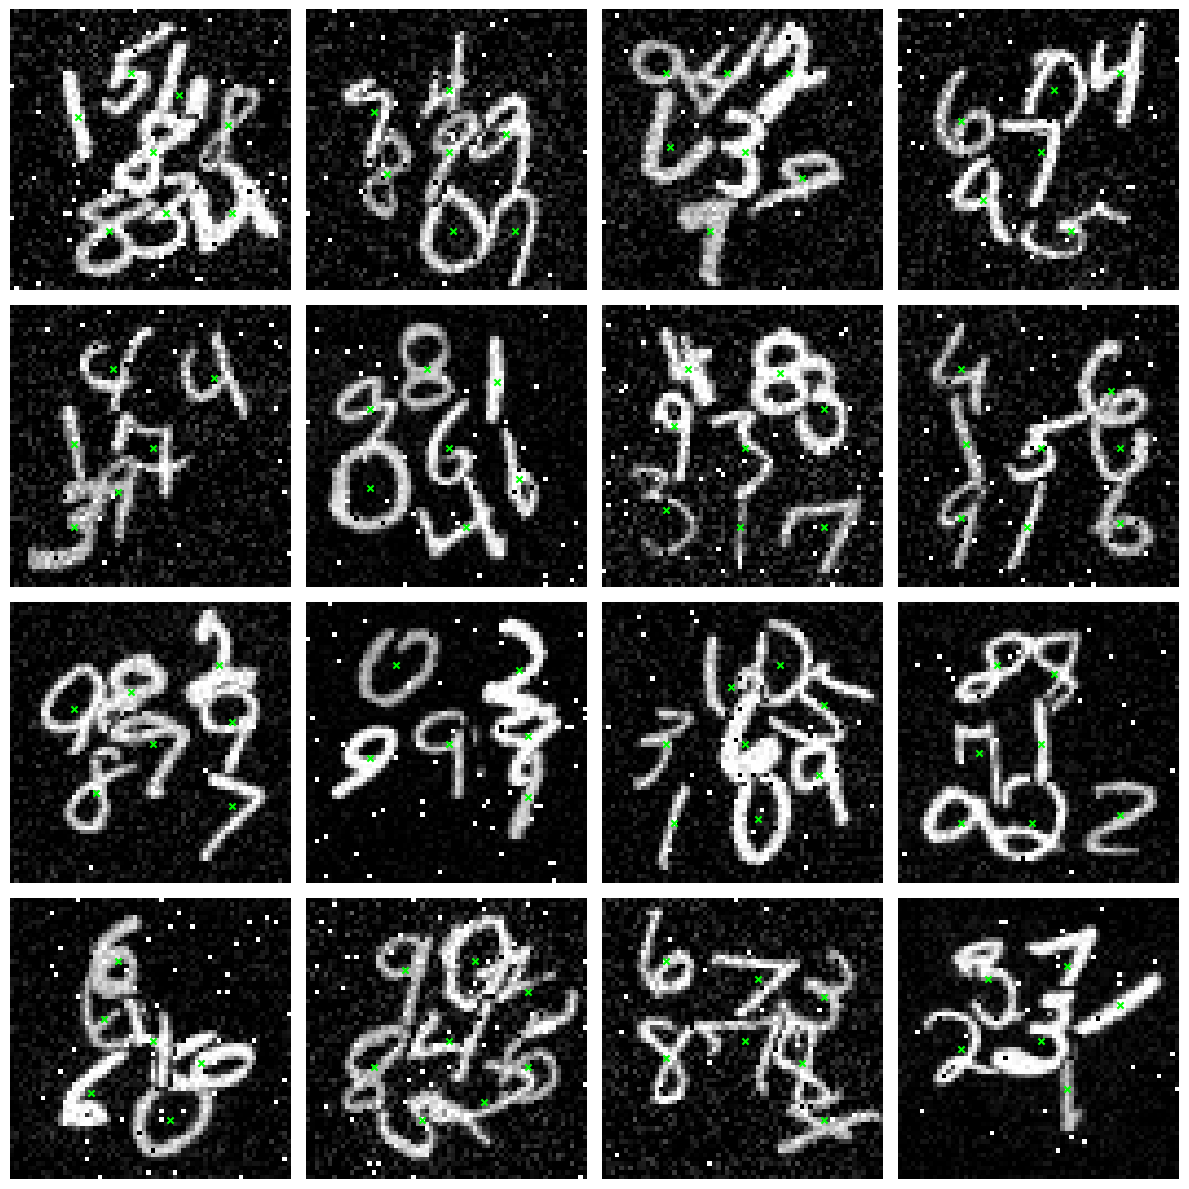

In [ ]:
def multihot_to_digits(multihot):
    """
    Convert a multi-hot vector into a list of digit labels.

    Example:
        [0, 1, 0, 0, 1, 0, 0, 0, 0, 1]
        becomes
        [1, 4, 9]
    """
    return np.where(multihot >= 0.5)[0].tolist()


from matplotlib.patches import Rectangle

def visualize_one_sample(images, labels, meta, idx=0):
    """Visualize one sample using digit center coordinates."""

    img = images[idx].squeeze()

    digits_present = multihot_to_digits(labels[idx])
    center_label = meta["center_labels"][idx]
    all_labels = meta["all_digit_labels"][idx]
    all_positions = meta["all_positions"][idx]
    n_digits = meta["num_digits"][idx]

    valid = all_labels >= 0
    labels = all_labels[valid]
    positions = all_positions[valid]

    fig, ax = plt.subplots(figsize=(6, 6))
    ax.imshow(img, cmap="gray")

    for (x, y), digit in zip(positions, labels):

        # Original 28x28 bounding box
        ax.add_patch(
            Rectangle(
                (x, y),
                28,
                28,
                fill=False,
                edgecolor="red",
                linewidth=2,
            )
        )

        # Center of the box
        cx = x + 14
        cy = y + 14

        ax.scatter(
            cx,
            cy,
            c="lime",
            s=80,
            marker="x",
        )

        ax.text(
            cx + 1,
            cy + 1,
            str(digit),
            color="yellow",
            fontsize=10,
            fontweight="bold",
        )

    ax.set_title(
        f"multi-label={digits_present}\n"
        f"center_label={center_label}, num_digits={n_digits}"
    )

    ax.axis("off")
    plt.tight_layout()
    plt.show()

def visualize_grid(images, labels, meta, num_samples=16):
    rows = int(np.sqrt(num_samples))
    cols = int(np.ceil(num_samples / rows))

    plt.figure(figsize=(12, 12))
    
    # randomly select indices to visualize
    indices = np.random.choice(len(images), size=num_samples, replace=False)
    
    for i in range(num_samples):
        plt.subplot(rows, cols, i + 1)
        visualize_one_sample(images, labels, meta, idx=indices[i])

    plt.tight_layout()
    plt.show()

# Visualize samples if the dataset has been loaded.
if "x_train" in globals():
    visualize_one_sample(x_train, y_train, meta_train, idx=0)
    visualize_grid(x_train, y_train, meta_train, num_samples=16)